In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import tomotopy as tp
from tomotopy.utils import Corpus
from tomotopy.coherence import Coherence
import matplotlib.pyplot as plt
import seaborn as sns
import pyLDAvis

In [4]:
df = pd.read_csv("cleaned_corpus.csv", index_col = 0, parse_dates = ['approved_date'])
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 995 entries, repacts:datasets/markdown/repacts/2016/ra_10924_2016.md to repacts:datasets/markdown/repacts/2022/ra_11933_2022.md
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   source           995 non-null    object        
 1   year             995 non-null    int64         
 2   month            995 non-null    object        
 3   path             995 non-null    object        
 4   basename         995 non-null    object        
 5   title            995 non-null    object        
 6   day              995 non-null    int64         
 7   year_extracted   995 non-null    int64         
 8   approved_date    995 non-null    datetime64[ns]
 9   cleaned_content  995 non-null    object        
dtypes: datetime64[ns](1), int64(3), object(6)
memory usage: 85.5+ KB


In [5]:
df['quarter'] = df.approved_date.dt.quarter
# q1 = df[df.quarters == 1]
# q2 = df[df.quarters == 2]
# q3 = df[df.quarters == 3]
# q4 = df[df.quarters == 4]

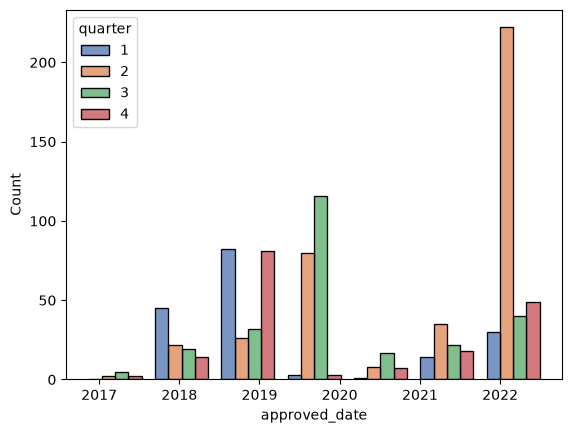

In [6]:
g = sns.histplot(x = 'approved_date', bins = 7, data = df, hue='quarter', multiple="dodge", shrink=.8, palette="deep")

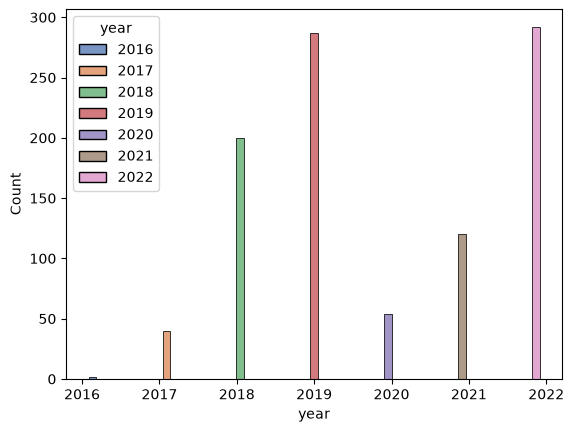

In [7]:
g = sns.histplot(x = 'year', bins = 7, data = df, hue='year', multiple="dodge", shrink=.8, palette="deep")

source: https://github.com/bab2min/tomotopy/blob/main/examples/lda_basic.py

In [8]:
df['year'].unique()

array([2016, 2017, 2018, 2019, 2020, 2021, 2022])

In [9]:
for year in df['year'].unique():
    period = df[df['year'] == year]
    total_docs = len(period)
    print(f"found {total_docs} record/s for year {year}")
    sample = period.sample(n=5 if total_docs > 5 else total_docs)
    print(sample['basename'].to_string(index=False))

found 2 record/s for year 2016
id
ra_10924_2016
ra_10923_2016
found 40 record/s for year 2017
id
ra_10960_2017
ra_10932_2017
ra_10944_2017
ra_10963_2017
ra_10947_2017
found 200 record/s for year 2018
id
ra_11017_2018
ra_10976_2018
ra_11096_2018
ra_11002_2018
ra_11083_2018
found 287 record/s for year 2019
id
ra_11344_2019
ra_11346_2019
ra_11451_2019
ra_11362_2019
ra_11373_2019
found 54 record/s for year 2020
id
ra_11470_2020
ra_11489_2020
ra_11507_2020
ra_11503_2020
ra_11468_2020
found 120 record/s for year 2021
id
ra_11638_2021
ra_11532_2021
ra_11581_2021
ra_11583_2021
ra_11552_2021
found 292 record/s for year 2022
id
ra_11879_2022
ra_11710_2022
ra_11695_2022
ra_11744_2022
ra_11774_2022


In [10]:
# import gensim.corpora as corpora
# from gensim.models.ldamodel import LdaModel

# # data_ready = df['cleaned_content']
# data_ready = [text.split() for text in df['cleaned_content']]
# id2word = corpora.Dictionary(data_ready)

# corpus = [id2word.doc2bow(text) for text in data_ready]

# # # # Build LDA model
# lda_model = LdaModel(corpus=corpus,
#                 id2word=id2word,
#                 num_topics=10,
#                 random_state=100,
#                 update_every=1,
#                 chunksize=10,
#                 passes=10,
#                 alpha='symmetric',
#                 iterations=100,
#                 per_word_topics=True

# lda_model.print_topics()

In [11]:
# def format_topics_sentences(ldamodel, corpus, texts):
#     # Init output
#     sent_topics_df = pd.DataFrame()

#     # Get main topic in each document
#     for i, row_list in enumerate(ldamodel[corpus]):
#         row = row_list[0] if ldamodel.per_word_topics else row_list
#         # print(row)
#         row = sorted(row, key=lambda x: (x[1]), reverse=True)
#         # Get the Dominant topic, Perc Contribution and Keywords for each document
#         for j, (topic_num, prop_topic) in enumerate(row):
#             if j == 0:  # => dominant topic
#                 wp = ldamodel.show_topic(topic_num)
#                 topic_keywords = ", ".join([word for word, prop in wp])
#                 s = pd.Series([int(topic_num), round(prop_topic,4), topic_keywords])
#                 sent_topics_df = pd.concat([sent_topics_df, s.to_frame().T], ignore_index=True)
#                 # sent_topics_df = sent_topics_df.append(pd.Series([int(topic_num), round(prop_topic,4), topic_keywords]), ignore_index=True)
#             else:
#                 break
#     sent_topics_df.columns = ['Dominant_Topic', 'Perc_Contribution', 'Topic_Keywords']

#     # Add original text to the end of the output
#     contents = pd.Series(texts)
#     sent_topics_df = pd.concat([sent_topics_df, contents], axis=1)
#     return(sent_topics_df)


# df_topic_sents_keywords = format_topics_sentences(ldamodel=lda_model, corpus=corpus, texts=data_ready)

# # Format
# df_dominant_topic = df_topic_sents_keywords.reset_index()
# df_dominant_topic.columns = ['Document_No', 'Dominant_Topic', 'Topic_Perc_Contrib', 'Keywords', 'Text']
# df_dominant_topic.head(10)

In [26]:
# period = df[df['year'] == 2016]
# raw_corpus_and_labeling_example(period, 0)
# for year in df['year'].unique():
#     period = df[df['year'] == year]
#     total_docs = len(period)
#     print(f"found {total_docs} record/s for year {year}")
#     rm_top = 0
corpus = tp.utils.Corpus()

for index, row in df.iterrows():
    # print(index, row['basename'], row['cleaned_content'])
    # break
    corpus.add_doc(row['cleaned_content'].split(' '), metadata=index)
# corpus.process(open(input_file, encoding='utf-8'))

# make LDA model and train
seed = 42
mdl = tp.DMRModel(k=20, min_cf=10, min_df=5, corpus=corpus, rm_top=8, seed=seed)
mdl.train(0, workers=1)
print('Num docs:', len(mdl.docs), ', Vocab size:', len(mdl.used_vocabs), ', Num words:', mdl.num_words)
print('Removed top words:', mdl.removed_top_words)
mdl.train(1000, workers=1)
mdl.summary()

# extract candidates for auto topic labeling
extractor = tp.label.PMIExtractor(min_cf=10, min_df=5, max_len=5, max_cand=10000, normalized=True)
cands = extractor.extract(mdl)

topics = []
top_topics = []
labeler = tp.label.FoRelevance(mdl, cands, min_df=5, smoothing=1e-2, mu=0.25)
for k in range(mdl.k):
    print("== Topic #{} ==".format(k))
    labels = ', '.join(label for label, score in labeler.get_topic_labels(k, top_n=5))
    print("Labels:", ', '.join(label for label, score in labeler.get_topic_labels(k, top_n=5)))
    topic_words = mdl.get_topic_words(k, top_n=10)
    for word, prob in topic_words:
        print(word, prob, sep='\t')
        topics.append({
            "topic": k,
            "word": word,
            "prob": prob,
        })
    top_word, top_prob = topic_words[0]
    top_topics.append({
        "topic": k,
        "word": top_word,
        "prob": top_prob,
        "labels": labels
    })
    print()

pd.DataFrame(topics).to_csv("topics.csv")
pd.DataFrame(top_topics).to_csv("top_topics.csv")

Num docs: 995 , Vocab size: 4039 , Num words: 563180
Removed top words: ['section', 'provide', 'this_act', 'service', 'philippine', 'public', 'government', 'act']
<Basic Info>
| DMRModel (current version: 0.14.0)
| 995 docs, 563180 words
| Total Vocabs: 16037, Used Vocabs: 4039
| Entropy of words: 7.28521
| Entropy of term-weighted words: 7.28521
| Removed Vocabs: section provide this_act service philippine public government act
| Metadata of docs and its distribution
|  repacts:datasets/markdown/repacts/2016/ra_10924_2016.md: 1
|  repacts:datasets/markdown/repacts/2016/ra_10923_2016.md: 1
|  repacts:datasets/markdown/repacts/2017/ra_10925_2017.md: 1
|  repacts:datasets/markdown/repacts/2017/ra_10926_2017.md: 1
|  repacts:datasets/markdown/repacts/2017/ra_10927_2017.md: 1
|  repacts:datasets/markdown/repacts/2017/ra_10928_2017.md: 1
|  repacts:datasets/markdown/repacts/2017/ra_10930_2017.md: 1
|  repacts:datasets/markdown/repacts/2017/ra_10931_2017.md: 1
|  repacts:datasets/markdown/re

In [24]:
# sampled_titles = df.sample(5).index
# topic_documents = pd.DataFrame()
topic_documents = []
top_topic_documents = []
for doc in mdl.docs:
    top_topics = doc.get_topics(top_n = 3)
    ra = df.loc[doc.metadata]
    for t in top_topics:
        topic, score = t
    #     # actual = df[df['cleaned_content'] == doc.words]
    #     # print(f"{actual['basename']}: #{topic} ({score:0.2f}%)")
    #     print(f"{df.loc[doc.metadata, 'basename']}: #{topic} ({score:0.2f}%)")
        topic_documents.append({
            "basename": ra['basename'],
            "year": ra['year'],
            "topic": topic,
            "score": score
        })
    top_topic, top_score = top_topics[0]
    top_topic_documents.append({
        "basename": ra['basename'],
        "year": ra['year'],
        "topic": top_topic,
        "score": top_score
    })

pd.DataFrame(topic_documents).to_csv("topic_documents.csv")
pd.DataFrame(top_topic_documents).to_csv("top_topic_documents.csv")


In [14]:
topic_term_dists = np.stack([mdl.get_topic_word_dist(k) for k in range(mdl.k)])
doc_topic_dists = np.stack([doc.get_topic_dist() for doc in mdl.docs])
doc_topic_dists /= doc_topic_dists.sum(axis=1, keepdims=True)
doc_lengths = np.array([len(doc.words) for doc in mdl.docs])
vocab = list(mdl.used_vocabs)
term_frequency = mdl.used_vocab_freq

prepared_data = pyLDAvis.prepare(
    topic_term_dists, 
    doc_topic_dists, 
    doc_lengths, 
    vocab, 
    term_frequency,
    start_index=0, # tomotopy starts topic ids with 0, pyLDAvis with 1
    sort_topics=False # IMPORTANT: otherwise the topic_ids between pyLDAvis and tomotopy are not matching!
)
pyLDAvis.save_html(prepared_data, 'ldavis.html')

TODO: How to handle entities? DA, DFA, (dept. etc)

In [15]:
print('(quarterly) Running LDA from raw corpus and Labeling')

# years = set(df['year'])
# quarters = set(df['quarter'])
# for y in years:
#     for q in quarters:
#         # collect into corpus obj
#         corpus = Corpus()
#         period = df[(df.year == y) & (df.quarter == q)]
#         total_docs = len(period)
#         print(f"found {total_docs} record/s for year {y} quarter {q}")
#         rm_top = 0
#         if total_docs > 0:
#             raw_corpus_and_labeling_example(period, rm_top)
#         else:
#             print(f'Skipping')

(quarterly) Running LDA from raw corpus and Labeling


In [16]:
# period = df[(df.year == 2019) & (df.quarter == 1)]
# print(f"found {len(period)} records for year {2019} quarter {1}")
# corpus = Corpus()
# if len(period):
#     for text in period['cleaned_content']:
#         corpus.add_doc(text.split())

# mdl = tp.LDAModel(min_df=5, rm_top=40, k=30, corpus=corpus)
# mdl.train(0)

# print('Num docs:{}, Num Vocabs:{}, Total Words:{}'.format(
#     len(mdl.docs), len(mdl.used_vocabs), mdl.num_words
# ))
# print('Removed Top words: ', *mdl.removed_top_words)

# # Let's train the model
# mdl.train(1000, workers=1)
# mdl.summary()

# topic_term_dists = np.stack([mdl.get_topic_word_dist(k) for k in range(mdl.k)])
# doc_topic_dists = np.stack([doc.get_topic_dist() for doc in mdl.docs])
# doc_topic_dists /= doc_topic_dists.sum(axis=1, keepdims=True)
# doc_lengths = np.array([len(doc.words) for doc in mdl.docs])
# vocab = list(mdl.used_vocabs)
# term_frequency = mdl.used_vocab_freq

# prepared_data = pyLDAvis.prepare(
#     topic_term_dists, 
#     doc_topic_dists, 
#     doc_lengths, 
#     vocab, 
#     term_frequency,
#     start_index=0, # tomotopy starts topic ids with 0, pyLDAvis with 1
#     sort_topics=False # IMPORTANT: otherwise the topic_ids between pyLDAvis and tomotopy are not matching!
# )
# pyLDAvis.save_html(prepared_data, 'ldavis.html')

In [17]:
# years = set(df['year'])
# quarters = set(df['quarter'])
# models = {}
# for y in years:
#     for q in quarters:
#         # collect into corpus obj
#         corpus = Corpus()
#         period = df[(df.year == y) & (df.quarter == q)] # pyright: ignore[reportUnknownVariableType]
#         print(f"found {len(period)} records for year {y} quarter {q}")
#         # if len(period):
#         #     for text in period['cleaned_content']: # pyright: ignore[reportUnknownVariableType]
#         #         corpus.add_doc(text.split()) # pyright: ignore[reportUnknownArgumentType, reportUnknownMemberType]

#         #     # training the model
#         #     seed = 357
#         #     model = tp.LDAModel(k = 40, corpus = corpus, seed = seed)
#         #     iters = 1000
#         #     model.train(iterations=iters, workers=1) # pyright: ignore[reportCallIssue, reportUnknownMemberType]
#         #     models[(y, q)] = model

#         #     sample_docs = 5
#         #     print("Samples:")
#         #     idx = 0
#         #     list_period = period.index.tolist()
#         #     for doc in model.docs:
#         #         if idx > sample_docs:
#         #             break
#         #         top_topics = doc.get_topics(top_n = 1)
#         #         topic, score = top_topics[0]
#         #         print(f"{df.loc[list_period[idx], 'basename']}: #{topic} ({score:0.2f}%)")
#         #         idx += 1
#         # else:
#         #     print("skipping, no records")

# # len(models)

In [18]:
# def top_words(model, k):
#     """Print the top words for topic k in a model."""
#     top_words = model.get_topic_words(topic_id = k, top_n = 10)
#     top_words = [f"{word} ({score:0.4f}%)" for (word, score) in top_words]
#     print(f"Topic {k}: {', '.join(top_words)}")

# for k,model in models.items(): # pyright: ignore[reportUnknownVariableType]
#     year, quarter = k # pyright: ignore[reportUnknownVariableType]
#     print(f"topics for year {year} quarter {quarter}")
#     for i in range(model.k): # pyright: ignore[reportUnknownArgumentType, reportUnknownMemberType]
#         top_words(model, i) # pyright: ignore[reportUnknownArgumentType]

# # TODO: consult excluding numbers, days of the week/month (incl. 'day'), other senate terms (article, senate, representative [excluding house kasi it can mean 2 things])
# #ALS naging al https://lawphil.net/statutes/repacts/ra2020/ra_11510_2020.html

comparing the topic words versus the top topic for some sample docs, I think I need to spread the topics more because for https://lawphil.net/statutes/repacts/ra2017/ra_10927_2017.html the focus was "An Act Designating Casinos as Covered Persons Under Republic Act No. 9160, Otherwise Known as the "Anti-Money Laundering Act of 2001", as Amended" but the top words were "Topic 0: case (0.0260%), provision (0.0180%), provide (0.0172%), follow (0.0144%), law (0.0144%)", or use them as stopwords (check TF-IDF first pano magwowork)

In [19]:
# for k,model in models.items():
#     year, quarter = k # pyright: ignore[reportUnknownVariableType]
#     print(f"words for year {year} quarter {quarter}")
#     doc = model.docs[0] # sample first document
#     word_to_topic = list(zip(doc, doc.topics))
#     for word in range(5):
#         word, topic = word_to_topic[word]
#         print(f"Word: {word}")
#         top_words(model, topic)

In [20]:
# for k,model in models.items():
#     topic_sizes = model.get_count_by_topics()
#     print("Number of words per topic:")
#     for i in range(model.k):
#         print(f"+ Topic #{i}: {topic_sizes[i]} words")


todo: coherence score https://www.geeksforgeeks.org/nlp/topic-modeling-using-latent-dirichlet-allocation-lda/